In [1]:
import networkx as nx
import numpy as np
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Point
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

In [32]:
def VEM_SBM_best(A, Xg=None, Xc=None, K=2, n_restarts=20, base_seed=0, max_iter=200, tol = 1e-6,verbose=False):
    best = None
    best_seed = None
    for s in range(base_seed, base_seed + n_restarts):
        np.random.seed(s)
        fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=200, tol = 1e-6, verbose=False)
        if best is None or fit['ELBO'][-1] > best['ELBO'][-1]:
            best = fit
            best_seed = s
    best['seed'] = best_seed
    return best

In [ ]:
# from pathlib import Path

# dfs = {}
# folder = Path('/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/EU regions/Datasets/NACE')
# for i,file in enumerate(folder.iterdir()):
#     dfs[i] = pd.read_excel('/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/EU regions/Datasets/NACE/' + file.name)

# df = dfs[0]
# for k in list(dfs.keys())[1:]:
#     df = df.merge(dfs[k].iloc[:,[0,2]], on='TIME')
# df = df.iloc[:512,]
# df = df.replace({':':'0'})
# for col in list(df.columns)[2:]:
#     df[col] = df[col].astype(float)

# ind_col = {}
# for i, col in enumerate(list(df.columns)):
#     ind_col[i] = col
# argmxs = df.iloc[:,2:].to_numpy().argmax(axis=1)
# df2 = df.iloc[:,:2]
# df2['sector'] = argmxs + 2
# df2['sector'] = df2['sector'].map(ind_col)

# df.to_csv('EU_regions_rawdata_per_settore.csv',index=False)
# df2.to_csv('EU_regions_settore_max.csv',index=False)

In [34]:
df = pd.read_csv('EU_regions_ALL_VARIABLES.csv')

In [35]:
df

,cname,region_code,name,qualityp,impartialityp,corruptionp,corruption_subPer,corruption_subExp,sector,Performance_group,Performance_group_short,Category of region
0,Austria,AT11,Burgenland (AT),0.686,1.367,0.600,0.837699,1.031630,"Public administration, defence, education, hum...",Strong Innovator +,Strong,transition
1,Austria,AT12,Niederösterreich,0.798,1.394,0.306,0.707117,0.613550,"Public administration, defence, education, hum...",Strong Innovator +,Strong,more developed
2,Austria,AT13,Wien,0.993,0.850,0.323,0.666202,0.687072,"Public administration, defence, education, hum...",Strong Innovator +,Strong,more developed
3,Austria,AT21,Kärnten,0.946,1.158,0.409,0.724308,0.788828,"Public administration, defence, education, hum...",Strong Innovator,Strong,more developed
4,Austria,AT22,Steiermark,0.794,1.448,0.549,0.954162,0.821141,"Public administration, defence, education, hum...",Strong Innovator,Strong,more developed
...,...,...,...,...,...,...,...,...,...,...,...,...
205,Slovenia,SI04,Zahodna Slovenija,0.097,0.245,-0.058,-0.596539,0.300393,"Wholesale and retail trade, transport, accommo...",Strong Innovator -,Strong,more developed
206,Slovakia,SK01,Bratislavský kraj,-0.770,-0.820,-1.596,-1.584680,-1.225650,"Public administration, defence, education, hum...",Moderate Innovator +,Moderate,more developed
207,Slovakia,SK02,Západné Slovensko,-0.572,-0.373,-0.867,-1.169240,-0.283260,Industry (except construction) [B-E],Emerging Innovator +,Emerging,less developed
208,Slovakia,SK03,Stredné Slovensko,-0.897,-0.155,-0.524,-0.964472,0.152559,Industry (except construction) [B-E],Emerging Innovator +,Emerging,less developed


## Continuous variables

All continuous variables are drawn from the **European Quality of Government Index (EQI) 2024** survey. They are standardised to mean 0 and standard deviation 1 across regions; higher values indicate better governance.

- **qualityp** : Perceived quality of public services (education, healthcare, law enforcement), based on citizens' ratings of the actual service delivery in their region.
- **impartialityp** : Perceived impartiality of public institutions, capturing whether citizens feel that public services are delivered fairly and equally regardless of personal connections, social status, or political affiliation.
- **corruptionp** : Overall perceived corruption, a composite of the two sub-indicators below.
- **corruption_subPer** : Perceived prevalence of corruption, measuring whether citizens believe corruption is widespread in their region's public sector.
- **corruption_subExp** : Experienced corruption, measuring whether citizens have personally encountered situations involving bribery or abuse of public office.

## Categorical variables

- **sector** : Dominant economic sector by employment in the region (4 categories), derived from Eurostat NACE employment data:
  - Public administration, defence, education, human health and social work activities [O–Q]
  - Industry, except construction [B–E]
  - Wholesale and retail trade, transport, accommodation and food service activities [G–I]
  - Financial and insurance activities [K]
- **Performance_group** : Regional Innovation Scoreboard classification (4 tiers), measuring the region's innovation capacity based on indicators such as R&D spending, patents, and high-tech employment:
  - Leader
  - Strong
  - Moderate
  - Emerging
- **Category of region** : EU cohesion policy eligibility category (3 levels), based on GDP per capita relative to the EU average:
  - More developed (> 100%)
  - Transition (75–100%)
  - Less developed (< 75%)

## Adjacency

In [36]:
data = gpd.read_file('NUTS_RG_20M_2024_3035.gpkg')
data.loc[147,'NUTS_ID'] = 'NL31'
data.loc[148,'NUTS_ID'] = 'NL33'
data.loc[196,'NUTS_ID'] = 'PT16'
data.loc[197,'NUTS_ID'] = 'PT17'
data.loc[199,'NUTS_ID'] = 'PT18'

In [37]:
gdf = data[data['NUTS_ID'].isin(df['region_code'])]
gdf.reset_index(drop=True,inplace=True)

n = len(gdf)
A = np.zeros((n, n), dtype=int)
for i in range(n):
    for j in range(i + 1, n):
        if gdf.geometry.iloc[i].touches(gdf.geometry.iloc[j]) or \
           gdf.geometry.iloc[i].intersects(gdf.geometry.iloc[j]):
            A[i, j] = 1
            A[j, i] = 1

np.fill_diagonal(A, 0)

## SBM

In [ ]:
sector_relabel = {}
for i, sec in enumerate(df['sector'].unique()):
    sector_relabel[sec] = i+1

performance_relabel = {}
for i, perf in enumerate(df['Performance_group_short'].unique()):
    performance_relabel[perf] = i+1

category_relabel = {}
for i, cat in enumerate(df['Category of region'].unique()):
    category_relabel[cat] = i+1

Xc = df.iloc[:,[-4,-2,-1]]

Xc['sector_mapped'] = Xc['sector'].map(sector_relabel)
Xc['performance_mapped'] = Xc['Performance_group_short'].map(performance_relabel)
Xc['category_mapped'] = Xc['Category of region'].map(category_relabel)

Xg = df.iloc[:,[3,4,5,6,7]]

In [43]:
Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_best(A, Xg=Xg, Xc=Xc.iloc[:,-3:], K=K, max_iter=50, tol=1e-6, verbose=False, n_restarts=10)
    Rs[K] = fit
    print(K)

2
3
4
5


In [7]:
import pickle

# with open('Rs_results_EUregions.pkl', 'wb') as f:
#     pickle.dump(Rs, f)

with open('Rs_results_EUregions.pkl', 'rb') as f:
    Rs = pickle.load(f)

In [44]:
Ks = [2,3,4,5]

for K in Ks:
    print(Rs[K]['vICL'])

-3555.7106466126916
-3524.6013463835175
-3492.239427288536
-3465.660189055666


In [45]:
partition = np.argmax(Rs[4]['r'], axis=1)
dtemp = df.copy()
dtemp['cluster'] = partition
gtemp = gdf.merge(dtemp[['region_code','cluster']],left_on='NUTS_ID',right_on='region_code')

## Plot

In [16]:
_INSET_CODES = {
    'Malta':           'MT',
    'Canarias (ES)':   'ES70',
    'Mayotte (FR)':    'FRY5',
    'Réunion (FR)':    'FRY4',
    'Martinique (FR)': 'FRY2',
    'Guadeloupe (FR)': 'FRY1',
    'Guyane (FR)':     'FRY3',
    'Madeira (PT)':    'PT30',
    'Açores (PT)':     'PT20',
}

_EU_NAMES = {
    'AT': 'Austria',     'BE': 'Belgium',      'BG': 'Bulgaria',
    'CY': 'Cyprus',      'CZ': 'Czechia',      'DE': 'Germany',
    'DK': 'Denmark',     'EE': 'Estonia',      'EL': 'Greece',
    'ES': 'Spain',       'FI': 'Finland',      'FR': 'France',
    'HR': 'Croatia',     'HU': 'Hungary',      'IE': 'Ireland',
    'IT': 'Italy',       'LT': 'Lithuania',    'LU': 'Luxembourg',
    'LV': 'Latvia',      'NL': 'Netherlands',  'PL': 'Poland',
    'PT': 'Portugal',    'RO': 'Romania',      'SE': 'Sweden',
    'SI': 'Slovenia',    'SK': 'Slovakia',
}

G = nx.from_numpy_array(A)

def plot_eu_network_with_insets(gdf_geo, G, fill_color="#AEE6CA",
                                node_color='blue', node_size=15, figsize=(14, 10), save=None):
    centroids = gdf_geo.geometry.centroid

    insets_present = [
        (name, code) for name, code in _INSET_CODES.items()
        if (gdf_geo['NUTS_ID'] == code).any()
    ]
    inset_ids = {code for _, code in insets_present}
    mainland_mask = ~gdf_geo['NUTS_ID'].isin(inset_ids)
    gdf_main = gdf_geo[mainland_mask]
    mainland_idx = set(gdf_main.index)

    fig = plt.figure(figsize=figsize)

    ax_main = fig.add_axes([0.01, 0.01, 0.70, 0.98])

    # Base NUTS-2 regions
    gdf_main.plot(ax=ax_main, color=fill_color, edgecolor='black', linewidth=0.5,alpha=0.4)

    # Country borders overlaid
    tmp_b = gdf_main[['NUTS_ID', 'geometry']].copy()
    tmp_b['_cc'] = tmp_b['NUTS_ID'].str[:2]
    tmp_b.dissolve(by='_cc').boundary.plot(
        ax=ax_main, color='#444444', linewidth=0.9, zorder=3
    )

    # Adjacency edges
    for i, j in G.edges():
        if i in mainland_idx and j in mainland_idx:
            ax_main.plot(
                [centroids.iloc[i].x, centroids.iloc[j].x],
                [centroids.iloc[i].y, centroids.iloc[j].y],
                color='black', lw=0.8, alpha=0.3,
            )

    # Nodes (paler)
    ax_main.scatter(centroids[mainland_mask].x, centroids[mainland_mask].y,
                    s=node_size, color=node_color, zorder=5, alpha=0.4)

    # Country name labels
    tmp = gdf_main.copy()
    tmp['_cc'] = tmp['NUTS_ID'].str[:2]
    for cc, grp in tmp.groupby('_cc'):
        label = _EU_NAMES.get(cc, cc)
        pt = grp.geometry.unary_union.centroid
        ax_main.text(pt.x, pt.y, label, ha='center', va='center',
                     fontsize=14.5, fontweight='bold', color='#111111', zorder=10,alpha=0.8)

    ax_main.axis('off')

    n = len(insets_present)
    if n:
        inset_left = 0.72
        inset_w    = 0.16
        inset_h    = 0.10
        gap        = 0.005
        total_h    = n * inset_h + (n - 1) * gap
        start_b    = (1.0 - total_h) / 2.0

        for i, (name, code) in enumerate(insets_present):
            mask = gdf_geo['NUTS_ID'] == code
            gdf_inset = gdf_geo[mask]
            inset_idx = set(gdf_inset.index)

            bottom = start_b + i * (inset_h + gap)
            ax_in = fig.add_axes([inset_left, bottom, inset_w, inset_h])

            gdf_inset.plot(ax=ax_in, color=fill_color, edgecolor='white', linewidth=0.5)

            for ii, jj in G.edges():
                if ii in inset_idx and jj in inset_idx:
                    ax_in.plot(
                        [centroids.iloc[ii].x, centroids.iloc[jj].x],
                        [centroids.iloc[ii].y, centroids.iloc[jj].y],
                        color='black', lw=0.8, alpha=0.3,
                    )

            ax_in.scatter(centroids[mask].x, centroids[mask].y,
                          s=node_size, color=node_color, zorder=5, alpha=0.4)

            b = gdf_inset.total_bounds
            dx = max((b[2] - b[0]) * 0.3, 50_000)
            dy = max((b[3] - b[1]) * 0.3, 50_000)
            ax_in.set_xlim(b[0] - dx, b[2] + dx)
            ax_in.set_ylim(b[1] - dy, b[3] + dy)
            ax_in.set_title(name, fontsize=7, pad=2, fontweight='bold')
            ax_in.axis('off')

            for spine in ax_in.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(0.7)
                spine.set_edgecolor("#d68b29")

    if save is not None:
        plt.savefig(f"{save}.png")
    plt.show()


/tmp/ipykernel_84574/146334605.py:72: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  pt = grp.geometry.unary_union.centroid


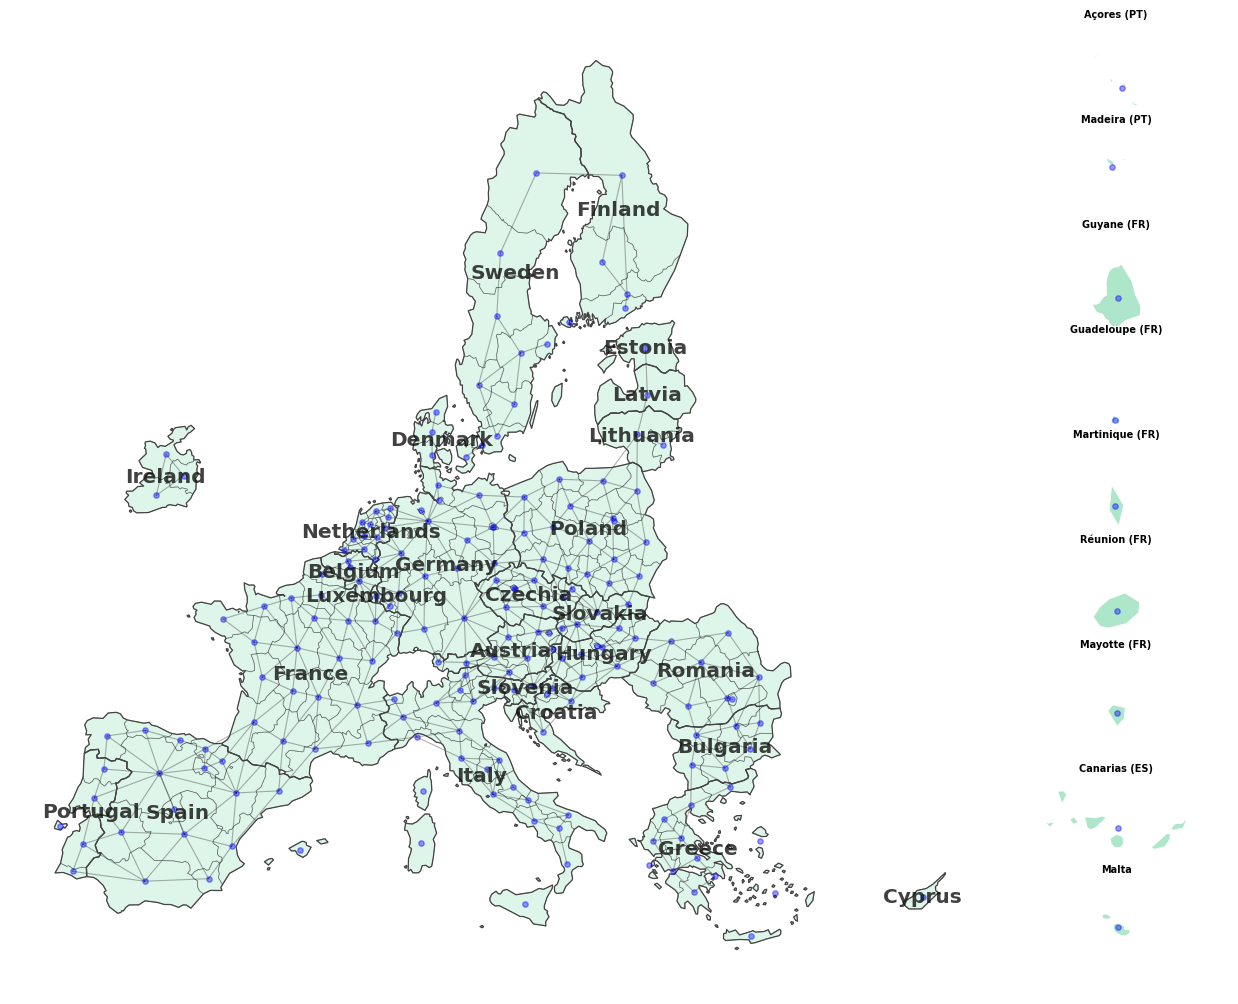

In [17]:
plot_eu_network_with_insets(gdf, G, save='network_eu_labels')

In [26]:
Rs[4]['phi_list'][2].round(3)

array([[0.471, 0.529, 0.   ],
       [0.117, 0.029, 0.854],
       [0.044, 0.   , 0.956],
       [0.27 , 0.416, 0.314]])

In [18]:
import matplotlib.patches as mpatches

_INSET_CODES = {
    'Malta':           'MT',
    'Canarias (ES)':   'ES70',
    'Mayotte (FR)':    'FRY5',
    'Réunion (FR)':    'FRY4',
    'Martinique (FR)': 'FRY2',
    'Guadeloupe (FR)': 'FRY1',
    'Guyane (FR)':     'FRY3',
    'Madeira (PT)':    'PT30',
    'Açores (PT)':     'PT20',
}

_EU_NAMES = {
    'AT': 'Austria',     'BE': 'Belgium',      'BG': 'Bulgaria',
    'CY': 'Cyprus',      'CZ': 'Czechia',      'DE': 'Germany',
    'DK': 'Denmark',     'EE': 'Estonia',      'EL': 'Greece',
    'ES': 'Spain',       'FI': 'Finland',      'FR': 'France',
    'HR': 'Croatia',     'HU': 'Hungary',      'IE': 'Ireland',
    'IT': 'Italy',       'LT': 'Lithuania',    'LU': 'Luxembourg',
    'LV': 'Latvia',      'NL': 'Netherlands',  'PL': 'Poland',
    'PT': 'Portugal',    'RO': 'Romania',      'SE': 'Sweden',
    'SI': 'Slovenia',    'SK': 'Slovakia',
}

def plot_eu_with_insets(gdf_data, column='cluster', cmap='Set2', title=None, figsize=(14, 10), save=None):
    insets_present = [
        (name, code) for name, code in _INSET_CODES.items()
        if (gdf_data['NUTS_ID'] == code).any()
    ]

    inset_ids = {code for _, code in insets_present}
    gdf_main = gdf_data[~gdf_data['NUTS_ID'].isin(inset_ids)]

    cats = sorted(gdf_data[column].unique())
    cat_colors = {1:"#e07de4", 2: "#7bc6f1", 3:"#bd101e", 4:"#3123ec"}

    fig = plt.figure(figsize=figsize)

    ax_main = fig.add_axes([0.01, 0.01, 0.70, 0.98])

    # NUTS-2 regions coloured by block
    gdf_main.plot(
        ax=ax_main,
        color=[cat_colors[c] for c in gdf_main[column]],
        edgecolor='white', linewidth=0.5, alpha=0.8
    )

    # Country borders overlaid
    tmp_b = gdf_main[['NUTS_ID', 'geometry']].copy()
    tmp_b['_cc'] = tmp_b['NUTS_ID'].str[:2]
    tmp_b.dissolve(by='_cc').boundary.plot(
        ax=ax_main, color='#444444', linewidth=1.2, zorder=3
    )

    # Country name labels
    tmp = gdf_main.copy()
    tmp['_cc'] = tmp['NUTS_ID'].str[:2]
    for cc, grp in tmp.groupby('_cc'):
        label = _EU_NAMES.get(cc, cc)
        pt = grp.geometry.unary_union.centroid
        ax_main.text(pt.x, pt.y, label, ha='center', va='center',
                     fontsize=14.5, color='#111111', zorder=10, fontweight='bold')

    ax_main.axis('off')

    n = len(insets_present)
    if n:
        inset_left = 0.72
        inset_w    = 0.16
        inset_h    = 0.10
        gap        = 0.005
        total_h    = n * inset_h + (n - 1) * gap
        start_b    = (1.0 - total_h) / 2.0

        for i, (name, code) in enumerate(insets_present):
            gdf_inset = gdf_data[gdf_data['NUTS_ID'] == code]
            bottom = start_b + i * (inset_h + gap)
            ax_in = fig.add_axes([inset_left, bottom, inset_w, inset_h])

            gdf_inset.plot(
                ax=ax_in,
                color=[cat_colors[c] for c in gdf_inset[column]],
                edgecolor='white', linewidth=0.5, alpha=0.8
            )

            b = gdf_inset.total_bounds
            dx = max((b[2] - b[0]) * 0.3, 50_000)
            dy = max((b[3] - b[1]) * 0.3, 50_000)
            ax_in.set_xlim(b[0] - dx, b[2] + dx)
            ax_in.set_ylim(b[1] - dy, b[3] + dy)
            ax_in.set_title(name, fontsize=7, pad=2, fontweight='bold')
            ax_in.axis('off')

            for spine in ax_in.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(0.7)
                spine.set_edgecolor('#aaaaaa')

    handles = [
        mpatches.Patch(facecolor=cat_colors[cat], label=f'Block {cat}')
        for cat in cats
    ]
    ax_main.legend(
        handles=handles, loc='upper left',
        fontsize=15, title_fontsize=10, framealpha=0.8,
    )

    if title:
        fig.text(0.38, 0.98, title, ha='center', va='top', fontsize=13)

    if save is not None:
        plt.savefig(f'{save}.png')

    plt.show()


/tmp/ipykernel_84574/3053396887.py:62: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  pt = grp.geometry.unary_union.centroid


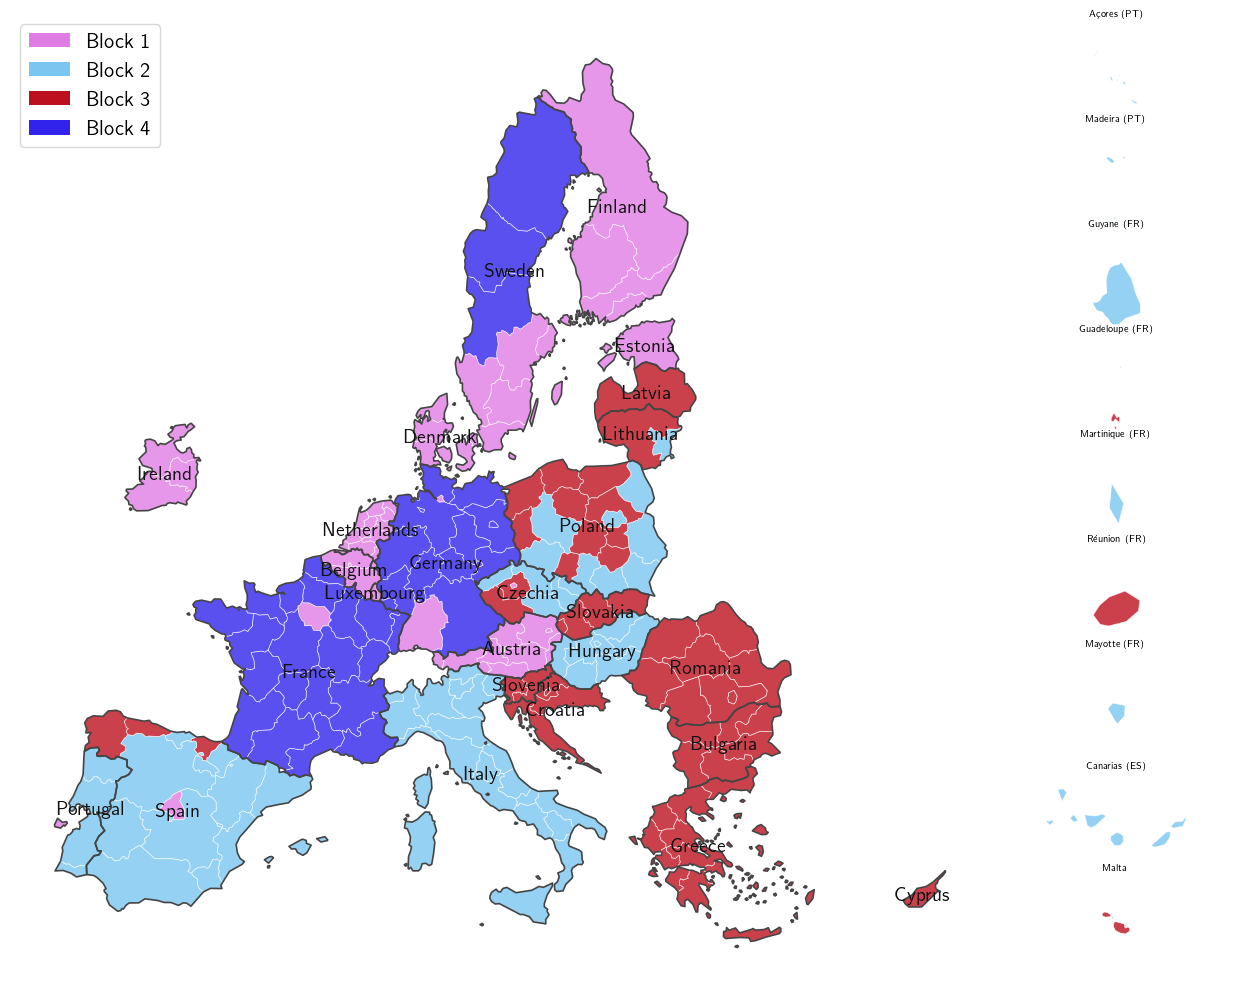

In [46]:
# with open('Rs_results_EUregions.pkl', 'rb') as f:
#     Rs_k4 = pickle.load(f)

dtemp = df.copy()
dtemp['cluster'] = partition + 1
gtemp_k4 = gdf.merge(dtemp[['region_code', 'cluster']], left_on='NUTS_ID', right_on='region_code')

plot_eu_with_insets(gtemp_k4, column='cluster', cmap='tab20', save='partition_eu_labels')

# # ── K=3, with unemployment ─────────────────────────────────────────────────────
# with open('Rs_results_EUregions+unemployment.pkl', 'rb') as f:
#     Rs_k3 = pickle.load(f)

# partition_k3 = np.argmax(Rs_k3[3]['r'], axis=1)
# dtemp_k3 = df.copy()
# dtemp_k3['cluster'] = partition_k3
# gtemp_k3 = gdf.merge(dtemp_k3[['region_code', 'cluster']], left_on='NUTS_ID', right_on='region_code')

# plot_eu_with_insets(gtemp_k3, column='cluster', cmap='Set2', title='SBM — K=3 (+ unemployment)')


In [ ]:
cat_colors = {0:"#e07de4", 1: "#7bc6f1", 2:"#bd101e", 3:"#3123ec"}

## Fuzzy profiling e metriche per cluster

In [27]:
U = Rs[4]['r']

In [28]:
contin_vars = ['qualityp', 'impartialityp','corruptionp', 'corruption_subPer', 'corruption_subExp']

dcont = pd.DataFrame(columns=contin_vars)

for contin_var in contin_vars:
    for i in range(4):
        dcont.loc[i,contin_var] = round((U[:,i] @ df[contin_var]) / (U[:,i].sum()), 3)
dcont

,qualityp,impartialityp,corruptionp,corruption_subPer,corruption_subExp
0,0.85,0.935,1.105,0.874,0.461
1,-0.97,-0.885,-1.087,-1.36,-1.727
2,-1.105,-0.999,-0.799,-0.339,-0.139
3,-0.04,-0.202,-0.35,-0.129,0.373


In [48]:
print(dcont.to_latex(float_format="%.3f"))

\begin{tabular}{llllll}
\toprule
 & qualityp & impartialityp & corruptionp & corruption_subPer & corruption_subExp \\
\midrule
0 & -0.521 & -0.779 & -0.573 & -0.185 & 0.207 \\
1 & 0.217 & 0.419 & 0.343 & 0.086 & 0.282 \\
2 & -1.120 & -0.945 & -1.159 & -1.264 & -1.864 \\
3 & 1.135 & 1.086 & 1.024 & 0.941 & 0.317 \\
\bottomrule
\end{tabular}



In [47]:
fuzzy_profiles_categ = {}

categ_vars = ['sector', 'Performance_group_short', 'Category of region']

for categ_var in categ_vars:
    categs = df[categ_var].unique()

    dj = pd.DataFrame(columns=categs)

    for categ in categs:
        for i in range(4):
            y = df[categ_var].apply(lambda x: 1 if x==categ else 0)
            dj.loc[i,categ] = round((y @ U[:,i])/(U[:,i].sum()), 4)
    fuzzy_profiles_categ[categ_var] = dj

In [48]:
d = {'Public administration, defence, education, human health and social work activities [O-Q]':'Public administration',
     'Industry (except construction) [B-E]':'Industry',
     'Wholesale and retail trade, transport, accommodation and food service activities [G-I]':'Wholesale and retail trade',
     'Financial and insurance activities [K]': 'Finance and insurance'}
fuzzy_profiles_categ['sector'].rename(columns=d, inplace=True)

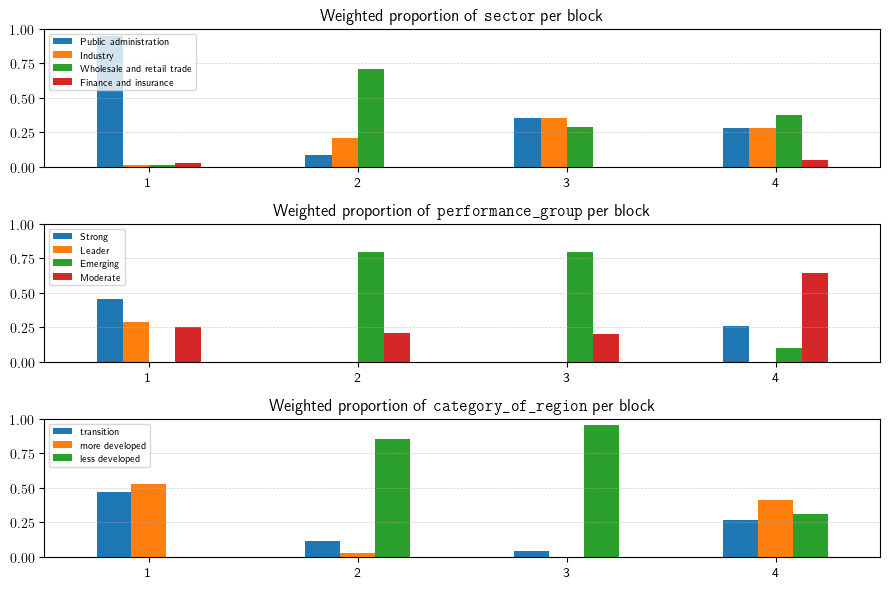

In [49]:
plt.rcParams['text.usetex'] = True
#ax.set_title(rf"Weighted proportion of \textbf{{\texttt{{{variable}}}}} per block")

titles = ['sector','performance_group','category_of_region']

fig, axes = plt.subplots(3,1,figsize=(9,6))

for i, cat in enumerate(categ_vars):
    ax = axes.flatten()[i]
    fuzzy_profiles_categ[cat].plot.bar(ax=ax)
    ax.set_title(rf"Weighted proportion of \textbf{{\texttt{{{titles[i]}}}}} per block")
    ax.legend(fontsize='x-small',loc='upper left')
    ax.set_ylim([0,1])
    ax.set_xticklabels(['1','2','3','4'],rotation=0)
    ax.grid(axis='y',linestyle='--',alpha=0.6,linewidth=0.5)
plt.tight_layout()
#plt.savefig('fuzzy_profiling_categ2.png')
plt.show()

In [60]:
Rs[4]['phi_list'][2].round(3)

array([[0.277, 0.723],
       [0.464, 0.536],
       [0.043, 0.957],
       [1.   , 0.   ]])

In [46]:
fuzzy_profiles_categ['Performance_group_short']

,Strong,Leader,Emerging,Moderate
0,0.0637,0.0,0.3258,0.6105
1,0.3948,0.0,0.1487,0.4565
2,0.0,0.0,0.843,0.157
3,0.4831,0.5138,0.0,0.0031


In [93]:
# moda
dtemp.groupby('cluster')[['sector', 'Performance_group', 'Category of region']].agg(pd.Series.mode)

,sector,Performance_group,Category of region
cluster,,,
0,"Wholesale and retail trade, transport, accommo...",Moderate Innovator -,less developed
1,"Public administration, defence, education, hum...",Moderate Innovator +,transition
2,"Wholesale and retail trade, transport, accommo...",Emerging Innovator -,less developed
3,"Public administration, defence, education, hum...",Innovation leader -,more developed


## Vecchi plot

In [ ]:
G = nx.from_numpy_array(A)

centroids = gdf.geometry.centroid

fig, ax = plt.subplots(figsize=(12, 12))
gdf.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.5)

for i, j in G.edges():
    ax.plot([centroids.iloc[i].x, centroids.iloc[j].x],
            [centroids.iloc[i].y, centroids.iloc[j].y],
            color='black', lw=0.8, alpha=0.3)

ax.scatter(centroids.x, centroids.y, s=15, color='blue', zorder=5)

plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(12, 12))
gtemp.plot(ax=ax, column='cluster', categorical=True, 
           cmap='Set2', edgecolor='white', linewidth=0.5, alpha=0.7,
           legend=True, legend_kwds={'title': 'Block'})
plt.axis('off')
plt.tight_layout()
plt.show()

# for i, j in G.edges():
#     ax.plot([centroids.iloc[i].x, centroids.iloc[j].x],
#             [centroids.iloc[i].y, centroids.iloc[j].y],
#             color='black', lw=0.8, alpha=0.2)

# plt.axis('off')
# plt.tight_layout()
# plt.show()

# + unemployment and tertiary education

In [52]:
dg = pd.read_excel('/home/domenicocangemi/Desktop/Data Lab/Paper nostri/SBM con attributi/EU regions/Datasets/Unemployment rate.xlsx', na_values=':')

df1 = df.merge(dg.iloc[:,[0,2]], left_on='region_code',right_on='GEO (Codes)')
df1 = df1.drop(columns=['GEO (Codes)'])
df1 = df1[['cname', 'region_code', 'name', 'qualityp', 'impartialityp',
       'corruptionp', 'corruption_subPer', 'corruption_subExp','Unemployment', 'sector',
       'Performance_group', 'Performance_group_short', 'Category of region']]

for i in df1[df1.Unemployment.isna()].index:
    country = df1.loc[i,'cname']
    val = df1[df1.cname == country]['Unemployment'].median()
    df1.loc[i, 'Unemployment'] = val

In [83]:
sector_relabel = {}
for i, sec in enumerate(df1['sector'].unique()):
    sector_relabel[sec] = i

performance_relabel = {}
for i, perf in enumerate(df1['Performance_group'].unique()):
    performance_relabel[perf] = i

category_relabel = {}
for i, cat in enumerate(df1['Category of region'].unique()):
    category_relabel[cat] = i

In [ ]:
Xc = df1.iloc[:,[-4,-3,-1]]

Xc['sector_mapped'] = Xc['sector'].map(sector_relabel)
Xc['performance_mapped'] = Xc['Performance_group'].map(performance_relabel)
Xc['category_mapped'] = Xc['Category of region'].map(category_relabel)

Xg = df1.iloc[:,3:9]

In [87]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_best(A, Xg=Xg, Xc=Xc.iloc[:,-3:], K=K, max_iter=50, tol=1e-6, verbose=False, n_restarts=20)
    Rs[K] = fit
    print(K)

2
3
4
5


In [88]:
Ks = [2,3,4,5]

for K in Ks:
    print(Rs[K]['vICL'])

-4572.992582446662
-4470.965428886279
-4624.218527107069
-4613.196331633544


In [ ]:
import pickle

# with open('Rs_results_EUregions+unemployment.pkl', 'wb') as f:
#     pickle.dump(Rs, f)

with open('Rs_results_EUregions+unemployment.pkl', 'rb') as f:
    Rs = pickle.load(f)

In [90]:
partition = np.argmax(Rs[3]['r'], axis=1)
partition

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 2, 2,
       2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 2, 2, 2,
       1, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2,
       2, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2])

In [91]:
dtemp = df.copy()
dtemp['cluster'] = partition
gtemp = gdf.merge(dtemp[['region_code','cluster']],left_on='NUTS_ID',right_on='region_code')

## Plot

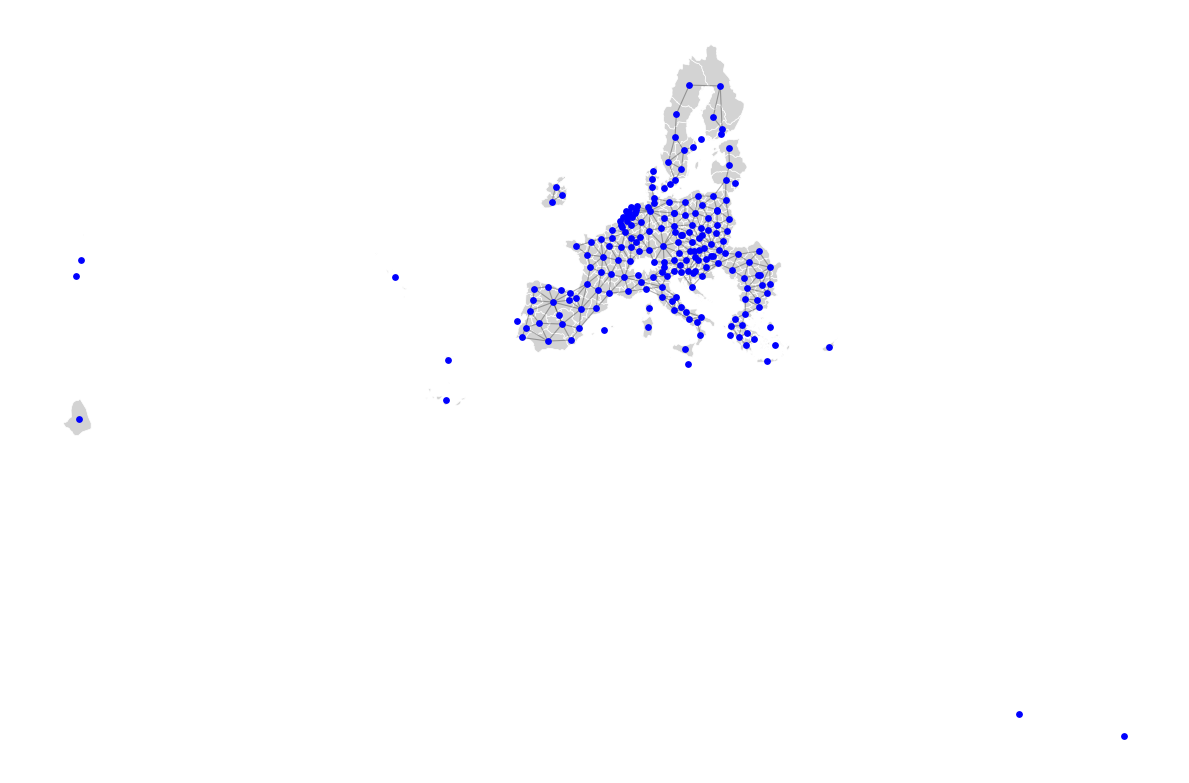

In [92]:
import numpy as np
import networkx as nx
import geopandas as gpd
import matplotlib.pyplot as plt

G = nx.from_numpy_array(A)

centroids = gdf.geometry.centroid

fig, ax = plt.subplots(figsize=(12, 12))
gdf.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.5)

for i, j in G.edges():
    ax.plot([centroids.iloc[i].x, centroids.iloc[j].x],
            [centroids.iloc[i].y, centroids.iloc[j].y],
            color='black', lw=0.8, alpha=0.3)

ax.scatter(centroids.x, centroids.y, s=15, color='blue', zorder=5)

plt.axis('off')
plt.tight_layout()
plt.show()

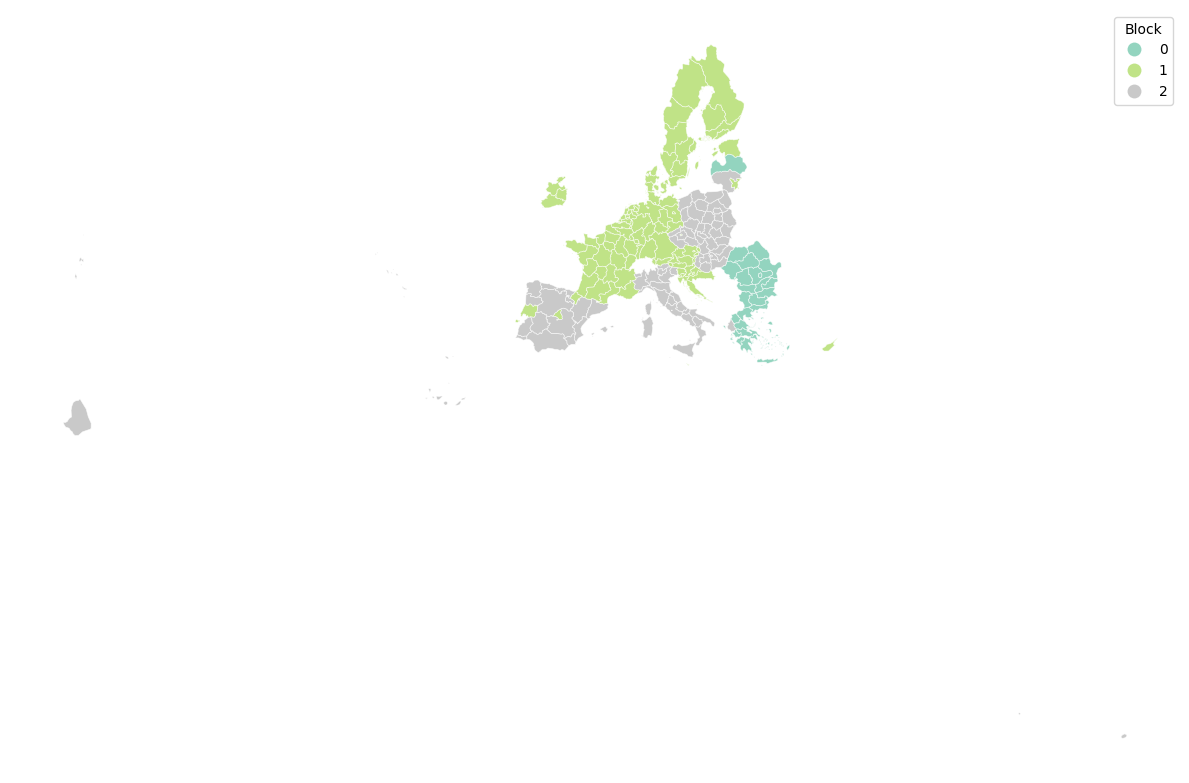

In [93]:
fig, ax = plt.subplots(figsize=(12, 12))
gtemp.plot(ax=ax, column='cluster', categorical=True, 
           cmap='Set2', edgecolor='white', linewidth=0.5, alpha=0.7,
           legend=True, legend_kwds={'title': 'Block'})
plt.axis('off')
plt.tight_layout()
plt.show()

# for i, j in G.edges():
#     ax.plot([centroids.iloc[i].x, centroids.iloc[j].x],
#             [centroids.iloc[i].y, centroids.iloc[j].y],
#             color='black', lw=0.8, alpha=0.2)

# plt.axis('off')
# plt.tight_layout()
# plt.show()